# WattRota — Kazanç potansiyeli ve kısıtlar

## 1. Araştırma sorusu

**Üç günlük fiyatlar tam bilindiğinde aynı fabrika kuralları altında ne kadar maliyet azalması bulunabiliyor? Kalan belirsizlik ne kadar ve fiyat hataları hangi kararları etkiliyor?**

2–4 Şubat, 4–6 Mayıs ve 5–7 Ekim 2026 fiyatları incelenir. Aynı sentetik firmanın talebi, kaynakları, stok hedefleri, minimum süreleri ve göreli bakım/teslim takvimi korunur. Sonuçlar gerçek fabrika tasarrufu değil, gerçekleşmiş PTF ile hesaplanmış senaryo sonuçlarıdır.

512 ürün sırası bileşiminden bütün işletme kontrollerini geçen 32 başlangıç oluşturuldu. Ana MILP bu başlangıçlarla sınırlanmadı; bütün tanımlı çizelgeleri araştırdı. Her tam bilgi araması 300 saniye ve %0,01 hedef göreli açık kullandı. Hedefe ulaşılmadıysa kalan aralık açıkça gösterilir.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
from itertools import permutations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

proje = Path.cwd()
if not (proje / "src").is_dir():
    proje = proje.parent
sys.path.insert(0, str(proje / "src"))
from firma_cizelgeleme import firma_verisini_oku, maliyet_ve_ozet
from ortak_plan_karsilastirmasi import tarihleri_tasi, arsivden_plan
from fiyat_tahmini import elektrik_fiyatlarini_oku
from kazanc_tanilari import plan_oku

folder = proje / "data/results/kazanc_potansiyeli"
izler = json.loads((folder / "deney_izleri.json").read_text(encoding="utf-8"))
for ad, beklenen in izler.items():
    assert hashlib.sha256((proje / ad).read_bytes()).hexdigest() == beklenen, ad
temel = firma_verisini_oku(proje)
ham = elektrik_fiyatlarini_oku(proje)
aralik = pd.read_csv(folder / "kazanc_araliklari.csv", parse_dates=["karar_zamani"])

## 2. Bulunan plan ile optimum arasındaki aralık

Alt sınır, maliyetin modelde altına inemeyeceği matematiksel değerdir; uygulanabilir bir plan değildir. Bulunan uygun maliyet, optimum için üst sınırdır. Bu iki değer arasındaki açıklık kapanmadan kesin optimum iddiası yapılmaz.

Referanstan bulunan uygun maliyete kadar olan azalma hesaplanmış bir planda gösterilmiştir. Referans eksi alt sınır ise olası azami azalmanın **üst sınırıdır**; elde edileceği kanıtlanmış kazanç değildir. Bu bir istatistiksel güven aralığı değildir.

In [2]:
uygun_planlar = {}
ortak = proje / "data/results/ortak_plan_deneyi"
eski_kararlar = pd.read_csv(ortak / "haftalik_kararlar.csv", parse_dates=["karar_zamani"])
for r in aralik.itertuples(index=False):
    karar = r.karar_zamani
    v = tarihleri_tasi(temel, karar)
    saatler = v["tesis_takvimi"]["tarih_saat"]
    v["fiyatlar"] = pd.DataFrame({"tarih_saat": saatler, "PTF (TL/MWh)": ham.reindex(saatler).to_numpy()})
    k = folder / (karar.strftime("%Y%m%d") + "_bilinen_fiyat_temel")
    b = json.loads((k / "sonuc.json").read_text(encoding="utf-8"))
    assert not b["temel_kurallar_degisti"]
    if r.en_iyi_plan_kaynagi == "tam_bilgi_arama":
        p, y = plan_oku(k)
    elif karar == pd.Timestamp("2026-10-05"):
        secilen_klasor = (folder / "20261005_basit_tahmin_temel" if r.en_iyi_plan_kaynagi == "son_yayinlanan_gun"
                         else ortak / "milp_kontrolu" / r.en_iyi_plan_kaynagi)
        p, y = plan_oku(secilen_klasor)
    else:
        pid = eski_kararlar[(eski_kararlar["karar_zamani"] == karar)
                           & (eski_kararlar["model"] == r.en_iyi_plan_kaynagi)].iloc[0]["secilen_plan"]
        p, y = arsivden_plan(ortak, pid, karar, pd.Timestamp("2025-10-06"))
    o = maliyet_ve_ozet(v, p, y)[-1]
    ref = maliyet_ve_ozet(v, v["referans_plan"], v["referans_yuklemeler"])[-1]
    assert np.isclose(ref.iloc[-1], r.referans_maliyet_tl, atol=0.02, rtol=0)
    assert np.isclose(o.iloc[-1], r.bulunan_en_iyi_maliyet_tl, atol=0.02, rtol=0)
    assert r.matematiksel_alt_sinir_tl <= o.iloc[-1] + 0.02
    assert np.isclose(b["cozum"]["alt_sinir_tl"], r.matematiksel_alt_sinir_tl, atol=0.02, rtol=0)
    uygun_planlar[karar] = (v, p, y)
print("Üç dönemin uygun planları asıl fabrika kurallarında yeniden doğrulandı.")
aralik.assign(karar_zamani=aralik["karar_zamani"].dt.strftime("%d.%m.%Y"))[["karar_zamani", "referans_maliyet_tl", "bulunan_en_iyi_maliyet_tl",
        "matematiksel_alt_sinir_tl", "bulunan_avantaj_tl", "cozulmemis_aralik_tl"]].round(2)

Üç dönemin uygun planları asıl fabrika kurallarında yeniden doğrulandı.
Out[2]: 
  karar_zamani  ...  cozulmemis_aralik_tl
0   02.02.2026  ...              20057.89
1   04.05.2026  ...               5089.93
2   05.10.2026  ...              22774.18

[3 rows x 6 columns]


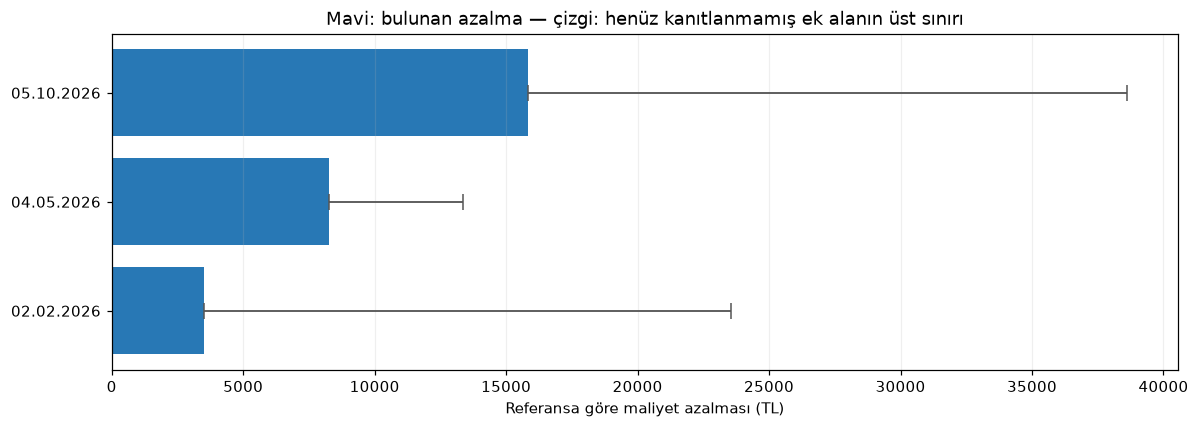

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
bulunan = aralik["bulunan_avantaj_tl"].to_numpy()
ek_alan = aralik["olasi_azami_avantaj_ust_siniri_tl"].to_numpy() - bulunan
ax.barh(aralik["karar_zamani"].dt.strftime("%d.%m.%Y"), bulunan, color="#2878b5",
        xerr=np.stack([np.zeros(len(aralik)), ek_alan]), capsize=5,
        error_kw={"ecolor": "#555555", "elinewidth": 1.2})
ax.set_xlabel("Referansa göre maliyet azalması (TL)")
ax.set_title("Mavi: bulunan azalma — çizgi: henüz kanıtlanmamış ek alanın üst sınırı")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 3. Stok, teslim ve üretim tamponları

5–7 Ekim'de bulunan tam bilgi planı incelenir. Tüketim sonrası stok tamponu, o saat başındaki stoktan tüketim ve minimum stoğun çıkarılmasıdır. Üretim aynı saatin sonunda eklenir. Sıfır tampon sınırın dolduğunu gösterir; tek başına kuralın ekonomik etkisini ölçmez.

In [4]:
ekim = folder / "20261005_bilinen_fiyat_temel"
stok = pd.read_csv(ekim / "stok_tamponlari.csv")
teslim = pd.read_csv(ekim / "teslim_tamponlari.csv")
emir = pd.read_csv(ekim / "is_emri_tamponlari.csv")
guc = pd.read_csv(ekim / "guc_tamponlari.csv")
print("Tam teslim sınırında biten sipariş:", int(teslim["tampon_saat"].abs().le(1e-6).sum()))
print("Tam iç bitiş sınırında biten iş emri:", int(emir["tampon_saat"].abs().le(1e-6).sum()))
print(f"En düşük ortak güç marjı: {guc['guc_tamponu_kw'].min():.2f} kW")
stok.round(2)

Tam teslim sınırında biten sipariş: 12
Tam iç bitiş sınırında biten iş emri: 5
En düşük ortak güç marjı: 50.00 kW
Out[4]: 
  urun_id stok_turu  ...  ust_sinir_saat  en_dusuk_tuketim_tamponu_ton
0    UR01     dokme  ...               0                          40.0
1    UR01   torbali  ...               0                         120.0
2    UR02     dokme  ...               0                          20.0
3    UR02   torbali  ...               0                           0.0
4    UR03     dokme  ...               0                          30.0
5    UR03   torbali  ...               0                          80.0

[6 rows x 5 columns]


In [5]:
pd.read_csv(ekim / "kaynak_ozeti.csv").rename(columns={
    "minimum_uretim_blogu_sayisi": "minimum sürede biten üretim bloğu",
    "minimum_durus_blogu_sayisi": "minimum sürede biten duruş bloğu"})

Out[5]: 
  kaynak_id  ...  minimum sürede biten duruş bloğu
0       H01  ...                                 0
1       H02  ...                                 1
2       P01  ...                                 0

[3 rows x 6 columns]


In [6]:
ilk_gun = temel["tesis_takvimi"]["tarih_saat"].min()
isler = temel["is_emirleri"]
pak = isler[(isler["islem_turu"] == "paketleme")
            & (isler["tamamlanma_siniri"] == ilk_gun + pd.Timedelta(hours=14))]
cap = temel["kaynak_urun"].query("kaynak_id == 'P01'").set_index("urun_id")["kapasite_ton_saat"]
net = (pak["miktar_ton"] / pak["urun_id"].map(cap)).sum()
gecis = temel["urun_gecisleri"].query("kaynak_id == 'P01'").set_index(["onceki_urun", "sonraki_urun"])["hazirlik_saat"]
hazirlik = min(sum(gecis.loc[a,b] for a,b in zip(["UR01"]+list(sira), sira) if a!=b)
               for sira in permutations(pak["urun_id"]))
print(f"İlk gün paketleme: {net:.0f} saat üretim + en az {hazirlik:.0f} saat hazırlık = {net+hazirlik:.0f} saat.")
print("Tamamlanma penceresi 14 saat; bu koşulda boşluk yok. UR03 öğütmesi yalnız H01'de yapılabiliyor.")

İlk gün paketleme: 12 saat üretim + en az 2 saat hazırlık = 14 saat.
Tamamlanma penceresi 14 saat; bu koşulda boşluk yok. UR03 öğütmesi yalnız H01'de yapılabiliyor.


## 4. Etiketlenmiş kural tanıları

Üç ayrı kopyada minimum stok, iç iş emri süresi veya minimum çalışma/duruş süresi gevşetildi. Asıl firma dosyaları ve ana sonuçlar değiştirilmedi. Müşteri teslim saatleri bu üç teşhiste korunur. Her teşhis 120 saniye çalıştırıldı ve asıl kurallara uygunluk ayrıca kontrol edildi.

Kural maliyetinin alt/üst değerleri iki modelin çözüm sınırlarından gelir. Alt değerin sıfır olması etkisinin sıfır olduğunu göstermez. Aynı nokta maliyetin bulunması da geniş çözüm aralıkları varken bir kuralın önemsizliğini kanıtlamaz.

In [7]:
tani = pd.read_csv(folder / "kural_teshis_araliklari.csv")
for ad in tani["tani"]:
    b = json.loads((folder / ("20261005_bilinen_fiyat_" + ad) / "sonuc.json").read_text(encoding="utf-8"))
    assert b["temel_kurallar_degisti"]
    assert "asil_fabrika_kurallarina_uyuyor" in b
print("Teşhislerde aynı uygun maliyet kaldı; kural etkisi mevcut aralıklarla kesin ayrıştırılamadı.")
tani.round(2)

Teşhislerde aynı uygun maliyet kaldı; kural etkisi mevcut aralıklarla kesin ayrıştırılamadı.
Out[7]: 
                    tani  ...  asil_kurallara_uyuyor
0        stok_alt_siniri  ...                   True
1    ic_is_emri_sureleri  ...                   True
2  minimum_blok_sureleri  ...                   True

[3 rows x 6 columns]


## 5. Fiyat hatasının belirli plan farkına etkisi

Yöntemin bulduğu plan ile tam bilgiyle bulunan uygun plan, aynı tahmin fiyatlarıyla sonradan karşılaştırılır. Pozitif gerçek iyileştirme, tam bilgi planının daha ucuz olduğunu gösterir. Tahminle hesaplanan iyileştirme negatifse yöntem bu iki seçenek arasında gerçekten daha ucuz olanı pahalı görüyor demektir.

Bu bir tanısal tekrar hesaplamadır: gerçekleşmiş gelecek fiyatlarıyla bulunmuş plan, geçmiş tahminli yönteme verilmiş gibi performans iddiası yapılmaz. Yorum yalnız bu plan çiftleri içindir.

In [8]:
ikili = pd.read_csv(folder / "ikili_plan_teshisi.csv", parse_dates=["karar_zamani"])
saatlik = pd.read_csv(folder / "saatlik_karar_hatasi.csv", parse_dates=["karar_zamani", "tarih_saat"])
toplam = saatlik.groupby(["karar_zamani", "model"])["fiyat_hatasi_karar_farki_etkisi_tl"].sum()
for r in ikili.itertuples(index=False):
    assert np.isclose(toplam.loc[r.karar_zamani,r.model],
                      r.tahmine_gore_iyilestirme_tl-r.gercek_iyilestirme_tl, atol=0.02, rtol=0)
ikili.assign(karar_zamani=ikili["karar_zamani"].dt.strftime("%d.%m.%Y"))[["karar_zamani", "model", "gercek_iyilestirme_tl", "tahmine_gore_iyilestirme_tl"]].round(2)

Out[8]: 
  karar_zamani  ...  tahmine_gore_iyilestirme_tl
0   02.02.2026  ...                         0.00
1   02.02.2026  ...                         0.00
2   04.05.2026  ...                      -201.73
3   04.05.2026  ...                     -1627.95
4   05.10.2026  ...                    -12998.96
5   05.10.2026  ...                    -11427.33

[6 rows x 4 columns]


In [9]:
onemli = saatlik[(saatlik["karar_zamani"] == pd.Timestamp("2026-10-05"))
                 & (saatlik["model"] == "hgb_duzeltme_365")].copy()
onemli["mutlak_etki"] = onemli["fiyat_hatasi_karar_farki_etkisi_tl"].abs()
onemli = onemli.nlargest(6, "mutlak_etki")
onemli.assign(tarih_saat=onemli["tarih_saat"].dt.strftime("%d.%m %H:%M"))[["tarih_saat", "gercek_fiyat", "tahmin_fiyat", "yontem_eksi_iyi_plan_enerji_kwh",
        "fiyat_hatasi_karar_farki_etkisi_tl"]].round(2)

Out[9]: 
      tarih_saat  ...  fiyat_hatasi_karar_farki_etkisi_tl
414  07.10 06:00  ...                            -5847.51
415  07.10 07:00  ...                            -5523.62
413  07.10 05:00  ...                            -2359.56
404  06.10 20:00  ...                            -2357.88
423  07.10 15:00  ...                            -1473.57
403  06.10 19:00  ...                            -1268.12

[6 rows x 5 columns]


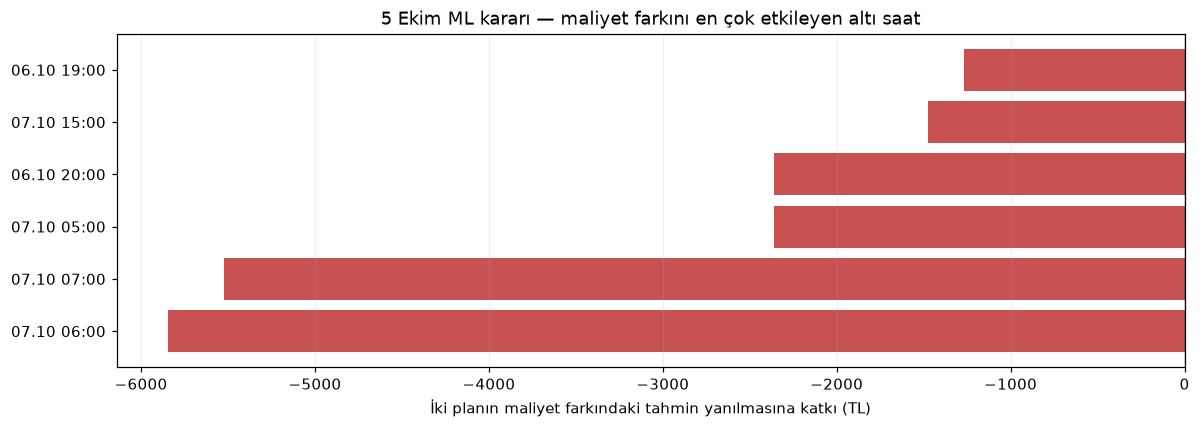

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.barh(onemli["tarih_saat"].dt.strftime("%d.%m %H:%M"),
        onemli["fiyat_hatasi_karar_farki_etkisi_tl"], color="#c85151")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("İki planın maliyet farkındaki tahmin yanılmasına katkı (TL)")
ax.set_title("5 Ekim ML kararı — maliyet farkını en çok etkileyen altı saat")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Çizelgedeki fark

Referans, basit tahminli 300 saniyelik arama ve tam fiyat bilgili 300 saniyelik arama gösterilir. Boş alan kaynak kapalı, taralı alan ürün hazırlığıdır. Sipariş ve stok hedefleri aynıdır.

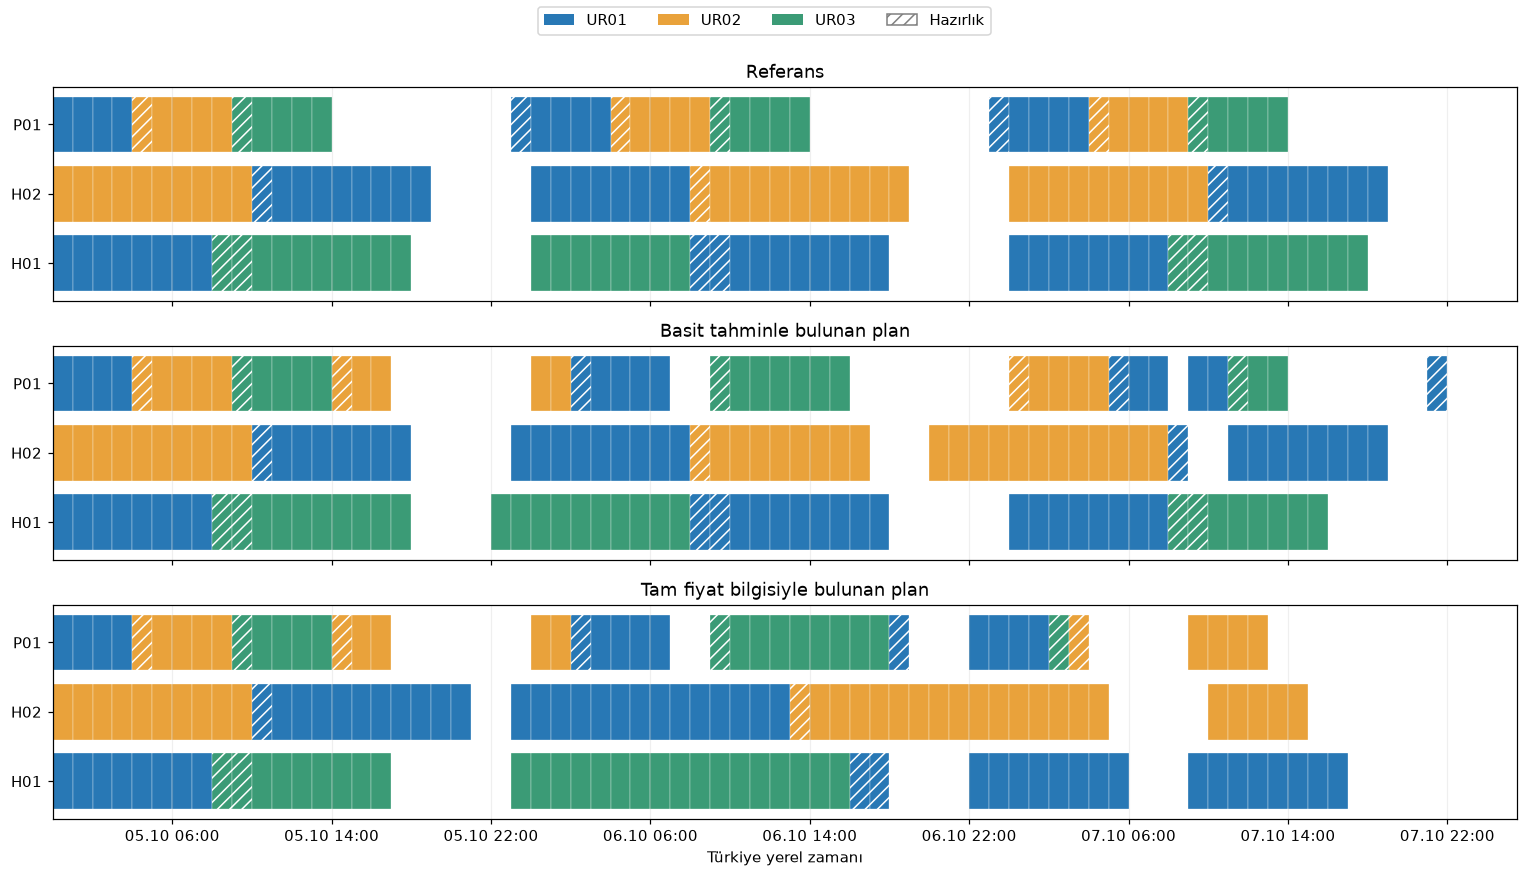

In [11]:
karar = pd.Timestamp("2026-10-05")
v, p, y = uygun_planlar[karar]
basit, _ = plan_oku(folder / "20261005_basit_tahmin_temel")
renk = {"UR01": "#2878b5", "UR02": "#e9a23b", "UR03": "#3b9b76"}
kaynaklar = ["H01", "H02", "P01"]
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, tablo, ad in zip(axes, [v["referans_plan"], basit, p],
                         ["Referans", "Basit tahminle bulunan plan", "Tam fiyat bilgisiyle bulunan plan"]):
    for i, r in enumerate(kaynaklar):
        for a in tablo[(tablo["kaynak_id"] == r) & (tablo["durum"] != "kapali")].itertuples(index=False):
            ax.barh(i, 1/24, left=mdates.date2num(a.tarih_saat), color=renk[a.urun_id],
                    hatch="///" if a.durum == "hazirlik" else None, edgecolor="white", linewidth=0.2)
    ax.set_yticks(range(3), kaynaklar)
    ax.set_title(ad)
    ax.grid(axis="x", alpha=0.2)
axes[-1].xaxis.set_major_locator(mdates.HourLocator(interval=8))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))
axes[-1].set_xlabel("Türkiye yerel zamanı")
fig.legend(handles=[Patch(facecolor=c, label=p) for p,c in renk.items()]
           + [Patch(facecolor="white", edgecolor="gray", hatch="///", label="Hazırlık")],
           loc="upper center", ncol=4)
plt.tight_layout(rect=(0,0,1,0.95))
plt.show()

## 7. Bulgular

Asıl fabrika koşulları korunarak referansa göre yaklaşık 3.494 TL, 8.255 TL ve 15.849 TL maliyet azalması veren uygun planlar bulundu. Dolayısıyla seçilmiş örneklerde optimizasyon fırsatı tamamen yok değildir. Buna karşılık optimum maliyetler kesinleşmedi; kalan aralıklar büyük olduğundan azami kazanç iddiası yapılamaz.

5–7 Ekim plan çiftinde yeni ML, 7 Ekim 06.00 ve 07.00 fiyatlarını önemli ölçüde düşük tahmin etti. Bu saatlerin iki plandaki enerji farkı büyük olduğundan fiyat yanılması maliyet karşılaştırmasını ters yönde etkiledi. Daha düşük genel MAE, bu kritik saatlerin doğru sıralanmasını garanti etmedi. Aynı örneklerde basit yöntemin de bütün önemli fiyat değişimlerini doğru sıraladığı gösterilemedi.

Kural teşhislerinin nokta maliyetleri değişmedi; geniş aralıklarla birlikte bu sonuç belirli bir kuralın maliyet etkisini sıfır saymaya yetmez. Fiziksel tamponlar, kısa arama ve fiyat hatasının karar etkisi ayrı değerlendirilmelidir. Bu çalışma ML'nin ekonomik üstünlüğünü kanıtlamaz; ekonomik hedefe neden henüz ulaşılamadığını daha somut inceler.

Yöntem, formüller ve yeniden üretim: `docs/kazanc-potansiyeli-ve-kisit-tanilari.md`.